In [1]:
%matplotlib inline

# Solution 2 — Build a DBA ring

**Build an electron storage ring from identical double-bend achromat (DBA) cells**.

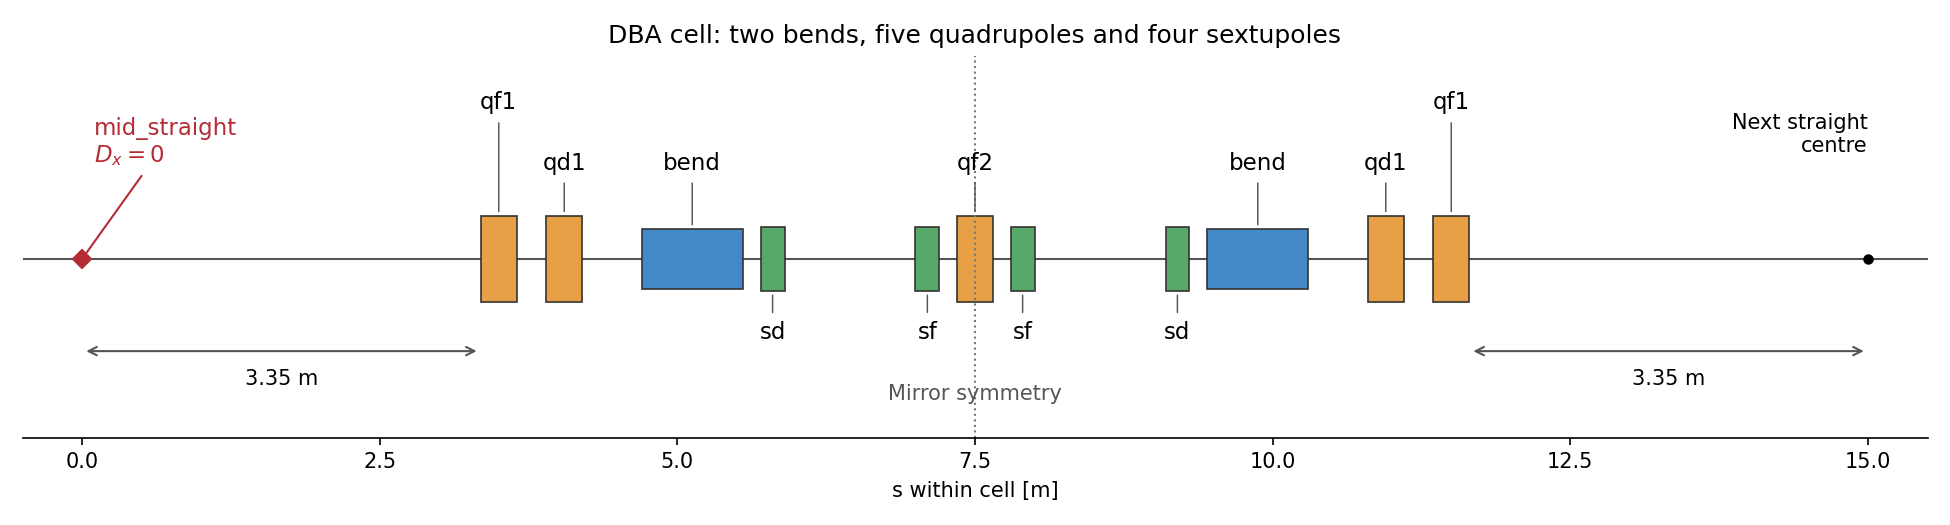

Indicative cell layout. Quadrupoles with the same name have the same strength.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical DBA cells | 16 |
| Phase advance per cell (horizontal / vertical) | 333° / 150.75° |
| Dipole type | Sector bend (`xt.Bend`) |
| Dipole length | 0.85 m |
| Quadrupole length | 0.30 m |
| Sextupole length | 0.20 m |
| Ring chromaticity | 0.5 / 0.5 |

Use the following **magnet-centre positions in the first half-cell**, including the cell centre:

| Family | Centre position [m] |
|---|---|
| qf1 | 3.50 |
| qd1 | 4.05 |
| Bend | 5.125 |
| qf2 | 7.50 |
| sf | 7.10 |
| sd | 5.80 |

### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Create xsuite environment

In [3]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

### Geometry parameters

In [4]:
env['angle_bend'] = 2 * np.pi / 16 / 2

env['l_cell'] = 15.
env['l_bend'] = 0.85
env['l_quad'] = 0.3
env['l_sext'] = 0.2

### Magnet strengths (initialized to zero)

In [5]:
env['kqf1'] = 0.0
env['kqf2'] = 0.0
env['kqd1'] = 0.0

env['ksf'] = 0.0
env['ksd'] = 0.0

### Define the magnets and build the cell

In [6]:
# Define elements
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)

env.new('qf1', xt.Quadrupole, length='l_quad', k1='kqf1')
env.new('qf2', xt.Quadrupole, length='l_quad', k1='kqf2')
env.new('qd1', xt.Quadrupole, length='l_quad', k1='kqd1')

env.new('sf', xt.Sextupole, length='l_sext', k2='ksf')
env.new('sd', xt.Sextupole, length='l_sext', k2='ksd')

env.new('mid_straight', xt.Marker)

'mid_straight'

### Define cell

Use `anchor='center'` and mirror each first-half position with an expression such as `at='l_cell - 3.50'`, as shown for `qf1` below. Place the central `qf2` only once.

In [7]:
cell = env.new_line(length=env['l_cell'], components=[
    env.place('mid_straight', at=0),

    # Quadrupoles
    env.place('qf1', anchor='center', at=3.50),
    env.place('qf1', anchor='center', at='l_cell - 3.50'),
    env.place('qf2', anchor='center', at=7.5),
    env.place('qd1', anchor='center', at=4.05),
    env.place('qd1', anchor='center', at='l_cell - 4.05'),

    # Bends
    env.place('bend', anchor='center', at=5.125),
    env.place('bend', anchor='center', at='l_cell - 5.125'),
    
    # Sextupoles
    env.place('sf', anchor='center', at=7.1),
    env.place('sf', anchor='center', at='l_cell - 7.1'),
    env.place('sd', anchor='center', at=5.8),
    env.place('sd', anchor='center', at='l_cell - 5.8'),
])

### Survey the cell

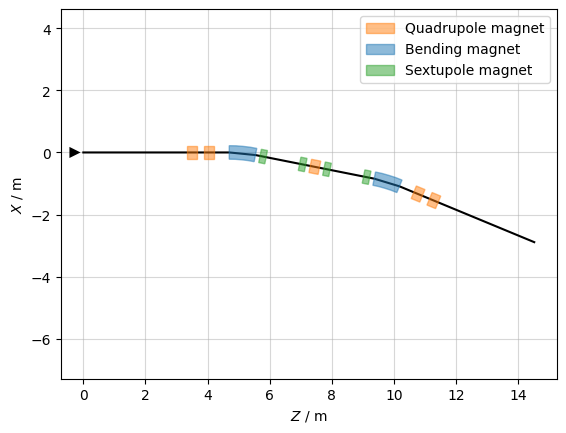

In [8]:
sv_cell = cell.survey()
sv_cell.plot()

### Set starting quadrupole strengths and compute initial twiss

In [9]:
env['kqf1'] = 3
env['kqd1'] = -3
env['kqf2'] = 3

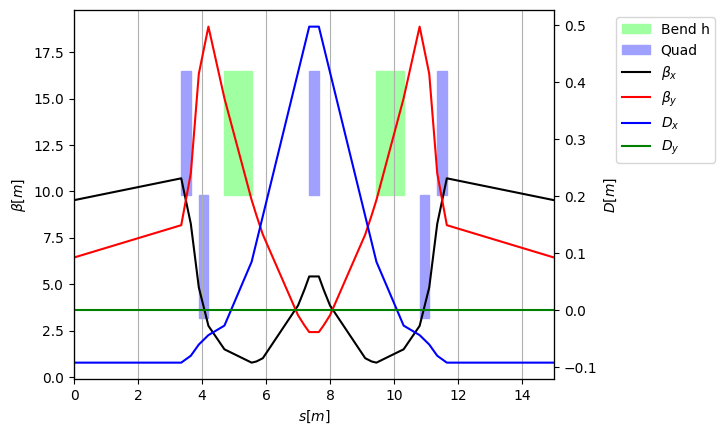

In [10]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell phase advances and dispersion

Impose $D_x=0$ at `mid_straight` to make the cell an achromat. Vary all three quadrupole strengths.

In [11]:
# Optimize cell periodic solution to obtain desired phase advances and dispersion
opt_cell = cell.match(
    solve=False,
    method='4d',
    vary=[
        xt.Vary('kqf1', limits=(0, 100), step=1e-5),
        xt.Vary('kqf2', limits=(0, 100), step=1e-5),
        xt.Vary('kqd1', limits=(-100, 0), step=1e-5),
    ],
    targets=[
        xt.TargetSet(qx=333/360., qy=150.75/360., tol=1e-8),
        xt.TargetSet(dx=0, at='mid_straight', tol=1e-8),
    ],
)

In [12]:
# Before optimization
opt_cell.target_status()

Target status:               alty = 1.2539e+00              
id state tag             tol_met       residue   current_val    target_val description                                 
0  ON    qx                False    -0.0500787      0.874921         0.925 'qx', val=0.925, tol=1e-08, weight=10       
1  ON    qy                False    -0.0694165      0.349333       0.41875 'qy', val=0.41875, tol=1e-08, weight=10     
2  ON    mid_straight_dx   False    -0.0916257    -0.0916257             0 ('dx', 'mid_straight'), val=0, tol=1e-08 ...


In [13]:
# Optimize
opt_cell.run_jacobian(30)

                                             
Optimize - start penalty: 1.254                             
Matching: model call n. 26 penalty = 3.9869e-09              
Optimize - end penalty:  3.98694e-09                            


In [14]:
# After optimization
opt_cell.target_status()
opt_cell.vary_status()

Target status:               nalty = 3.9869e-09              
id state tag             tol_met       residue   current_val    target_val description                                 
0  ON    qx                 True  -4.41802e-11         0.925         0.925 'qx', val=0.925, tol=1e-08, weight=10       
1  ON    qy                 True   2.11692e-12       0.41875       0.41875 'qy', val=0.41875, tol=1e-08, weight=10     
2  ON    mid_straight_dx    True  -3.96233e-10  -3.96233e-10             0 ('dx', 'mid_straight'), val=0, tol=1e-08 ...
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf1           0       3.18653         100             3         1e-05             1
1  ON        OK  kqf2           0       2.92835         100             3         1e-05             1
2  ON        OK  kqd1        -100      -3.16787           0            -3         1e-05             1


### Inspect the matched cell optics

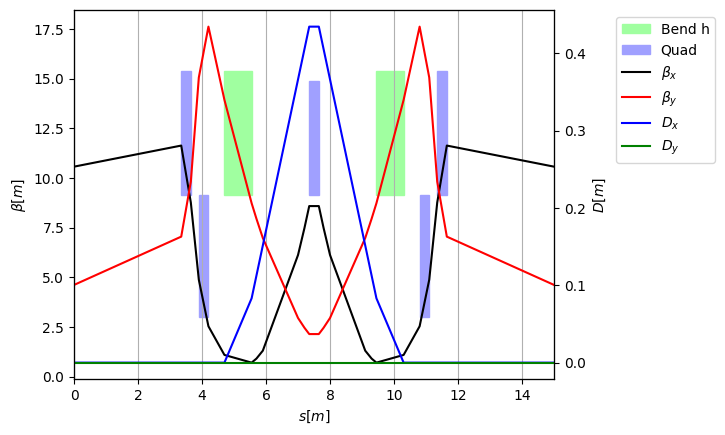

In [15]:
tw_cell = cell.twiss4d()
tw_cell.plot()

In [16]:
# Inspect the dispersion at the straight centre
tw_cell.rows['mid_straight'].cols['dx dpx']

TwissTable: 1 row, 3 cols
name                    dx           dpx
mid_straight  -3.96233e-10   1.45121e-12

### Assemble the ring

In [17]:
n_cells = 16
ring = n_cells * cell

### Give unique names to all elements

In [18]:
ring.replace_all_repeated_elements()

### Survey

In [19]:
sv = ring.survey()

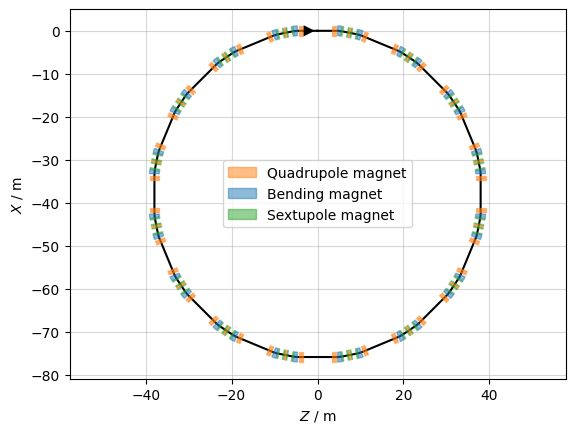

In [20]:
sv.plot()

### Full-ring optics

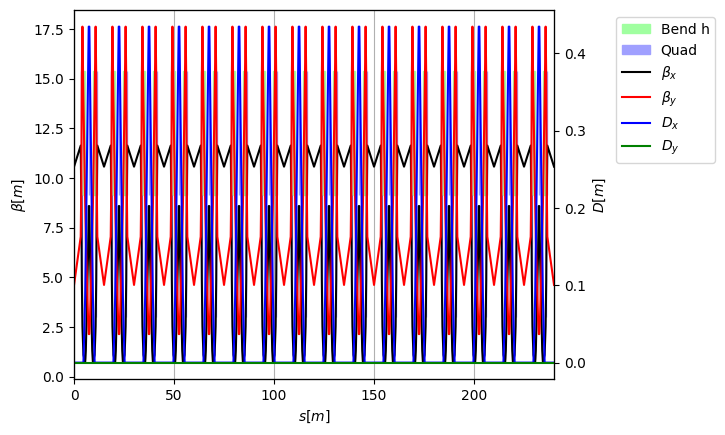

In [21]:
tw_ring = ring.twiss4d()
tw_ring.plot()

In [22]:
# Inspect tunes
tw_ring.qx, tw_ring.qy

(14.799999999380832, 6.700000000033807)

### Correct the chromaticities

In [23]:
opt_chrom = ring.match(
    solve=False,
    method='4d',
    vary=[
        xt.Vary('ksf', limits=(0, 100), step=1e-3),
        xt.Vary('ksd', limits=(-100, 0), step=1e-3),
    ],
    targets=xt.TargetSet(dqx=0.5, dqy=0.5, tol=0.001),
)

In [24]:
opt_chrom.run_jacobian(30)

                                             
Optimize - start penalty: 34.64                             
Matching: model call n. 11 penalty = 2.9349e-07              
Optimize - end penalty:  2.93488e-07                            


In [ ]:
opt_chrom.target_status()
opt_chrom.vary_status()

### Final tunes and chromaticities

In [26]:
tw_ring = ring.twiss4d()
print(f'Tunes: {tw_ring.qx:.6f} / {tw_ring.qy:.6f}')
print(f'Chromaticities: {tw_ring.dqx:.6f} / {tw_ring.dqy:.6f}')

Tunes: 14.800000 / 6.700000
Chromaticities: 0.500000 / 0.500000


### Save the ring

In [27]:
ring.to_json('ring_dba.json')